<a href="https://colab.research.google.com/github/Farouk41/Customer_Churn_Project/blob/main/Customer_Churn_Solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Churn Analysis & Prediction
End-to-end project: data cleaning, EDA, outlier handling, encoding, modeling (Logistic Regression & Decision Tree) and evaluation on the Telco Customer Churn dataset.

## 1. Dataset Loading

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

In [ ]:
df = pd.read_csv("Telco-Customer-Churn.csv")
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [ ]:
print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paperles

## 2. Data Understanding

In [ ]:
target = 'Churn'
id_col = 'customerID'
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']   # TotalCharges is stored as text for now
binary_numeric = ['SeniorCitizen']                            # already 0/1
categorical_cols = [c for c in df.columns if c not in numeric_cols + binary_numeric + [target, id_col]]

print("Target variable        :", target)
print("Customer ID column     :", id_col)
print("Numerical features     :", numeric_cols)
print("Binary numeric feature :", binary_numeric)
print("Categorical features   :", categorical_cols)
print("\nData types:\n", df.dtypes)
print("\nMissing values (as NaN):\n", df.isnull().sum()[df.isnull().sum() > 0])
print("(none shown above means no NaN yet - but TotalCharges is a string column, so hidden blanks may exist)")

Target variable        : Churn
Customer ID column     : customerID
Numerical features     : ['tenure', 'MonthlyCharges', 'TotalCharges']
Binary numeric feature : ['SeniorCitizen']
Categorical features   : ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Data types:
 customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalChar

## 3. Data Cleaning

In [ ]:
# TotalCharges is text because some cells contain blank spaces
print("Blank TotalCharges cells:", (df['TotalCharges'].str.strip() == '').sum())
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing TotalCharges after conversion:", df['TotalCharges'].isnull().sum())
df[df['TotalCharges'].isnull()][['customerID','tenure','MonthlyCharges','TotalCharges','Churn']]

Blank TotalCharges cells: 11
Missing TotalCharges after conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


All rows with a missing `TotalCharges` have `tenure = 0` → these are brand-new customers who have not been billed yet, so their total charges are logically **0**. We fill with 0 (more meaningful than mean/median here).

In [ ]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)
print("Missing TotalCharges now:", df['TotalCharges'].isnull().sum())
print("Duplicated rows:", df.duplicated().sum())

# Remove customerID before modeling
df = df.drop(columns=['customerID'])
print("Shape after dropping customerID:", df.shape)

Missing TotalCharges now: 0
Duplicated rows: 0
Shape after dropping customerID: (7043, 20)


## 4. Exploratory Data Analysis

### 4.1 Numerical feature distributions

            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000   7043.000000
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047   2266.794470
min       0.000000       18.250000      0.000000
25%       9.000000       35.500000    398.550000
50%      29.000000       70.350000   1394.550000
75%      55.000000       89.850000   3786.600000
max      72.000000      118.750000   8684.800000


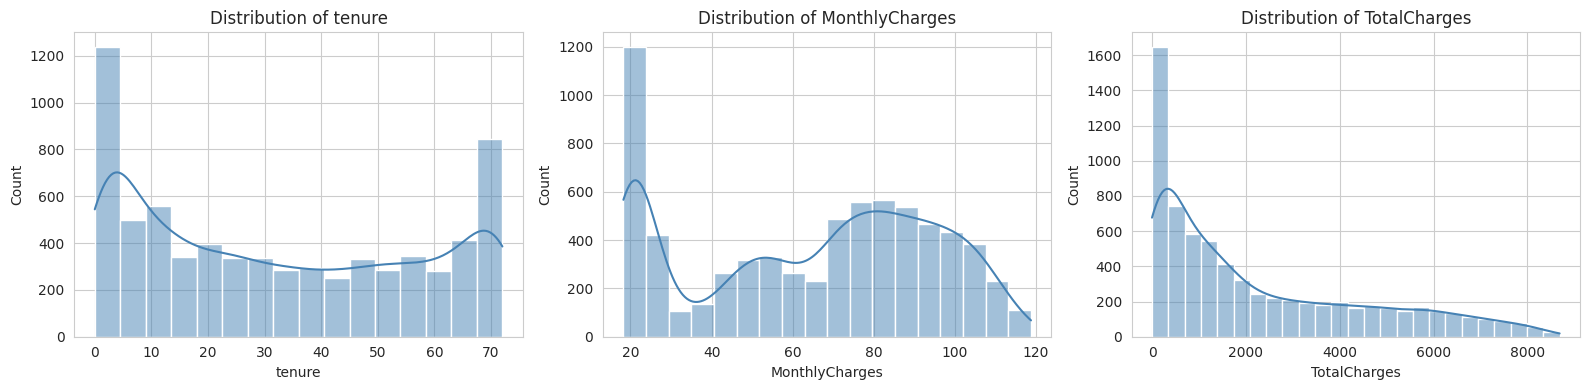

In [ ]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
print(df[numeric_cols].describe())
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, numeric_cols):
    sns.histplot(df[c], kde=True, ax=ax, color='steelblue')
    ax.set_title(f'Distribution of {c}')
plt.tight_layout(); plt.show()

### 4.2 Numerical features vs Churn

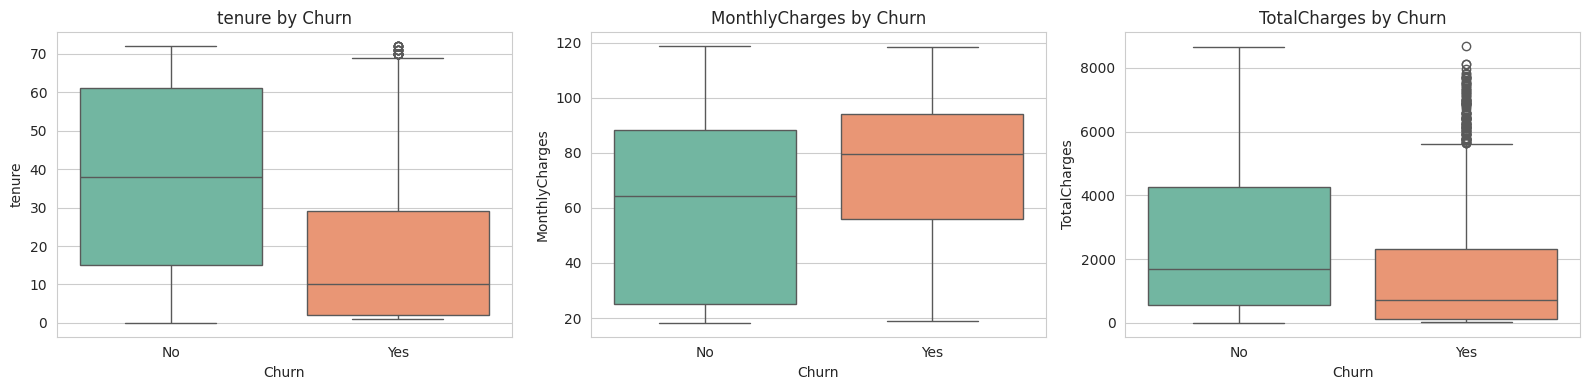

       tenure  MonthlyCharges  TotalCharges
Churn                                      
No      37.57           61.27       2549.91
Yes     17.98           74.44       1531.80


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, numeric_cols):
    sns.boxplot(data=df, x='Churn', y=c, ax=ax, palette='Set2')
    ax.set_title(f'{c} by Churn')
plt.tight_layout(); plt.show()
print(df.groupby('Churn')[numeric_cols].mean().round(2))

### 4.3 Categorical feature distributions

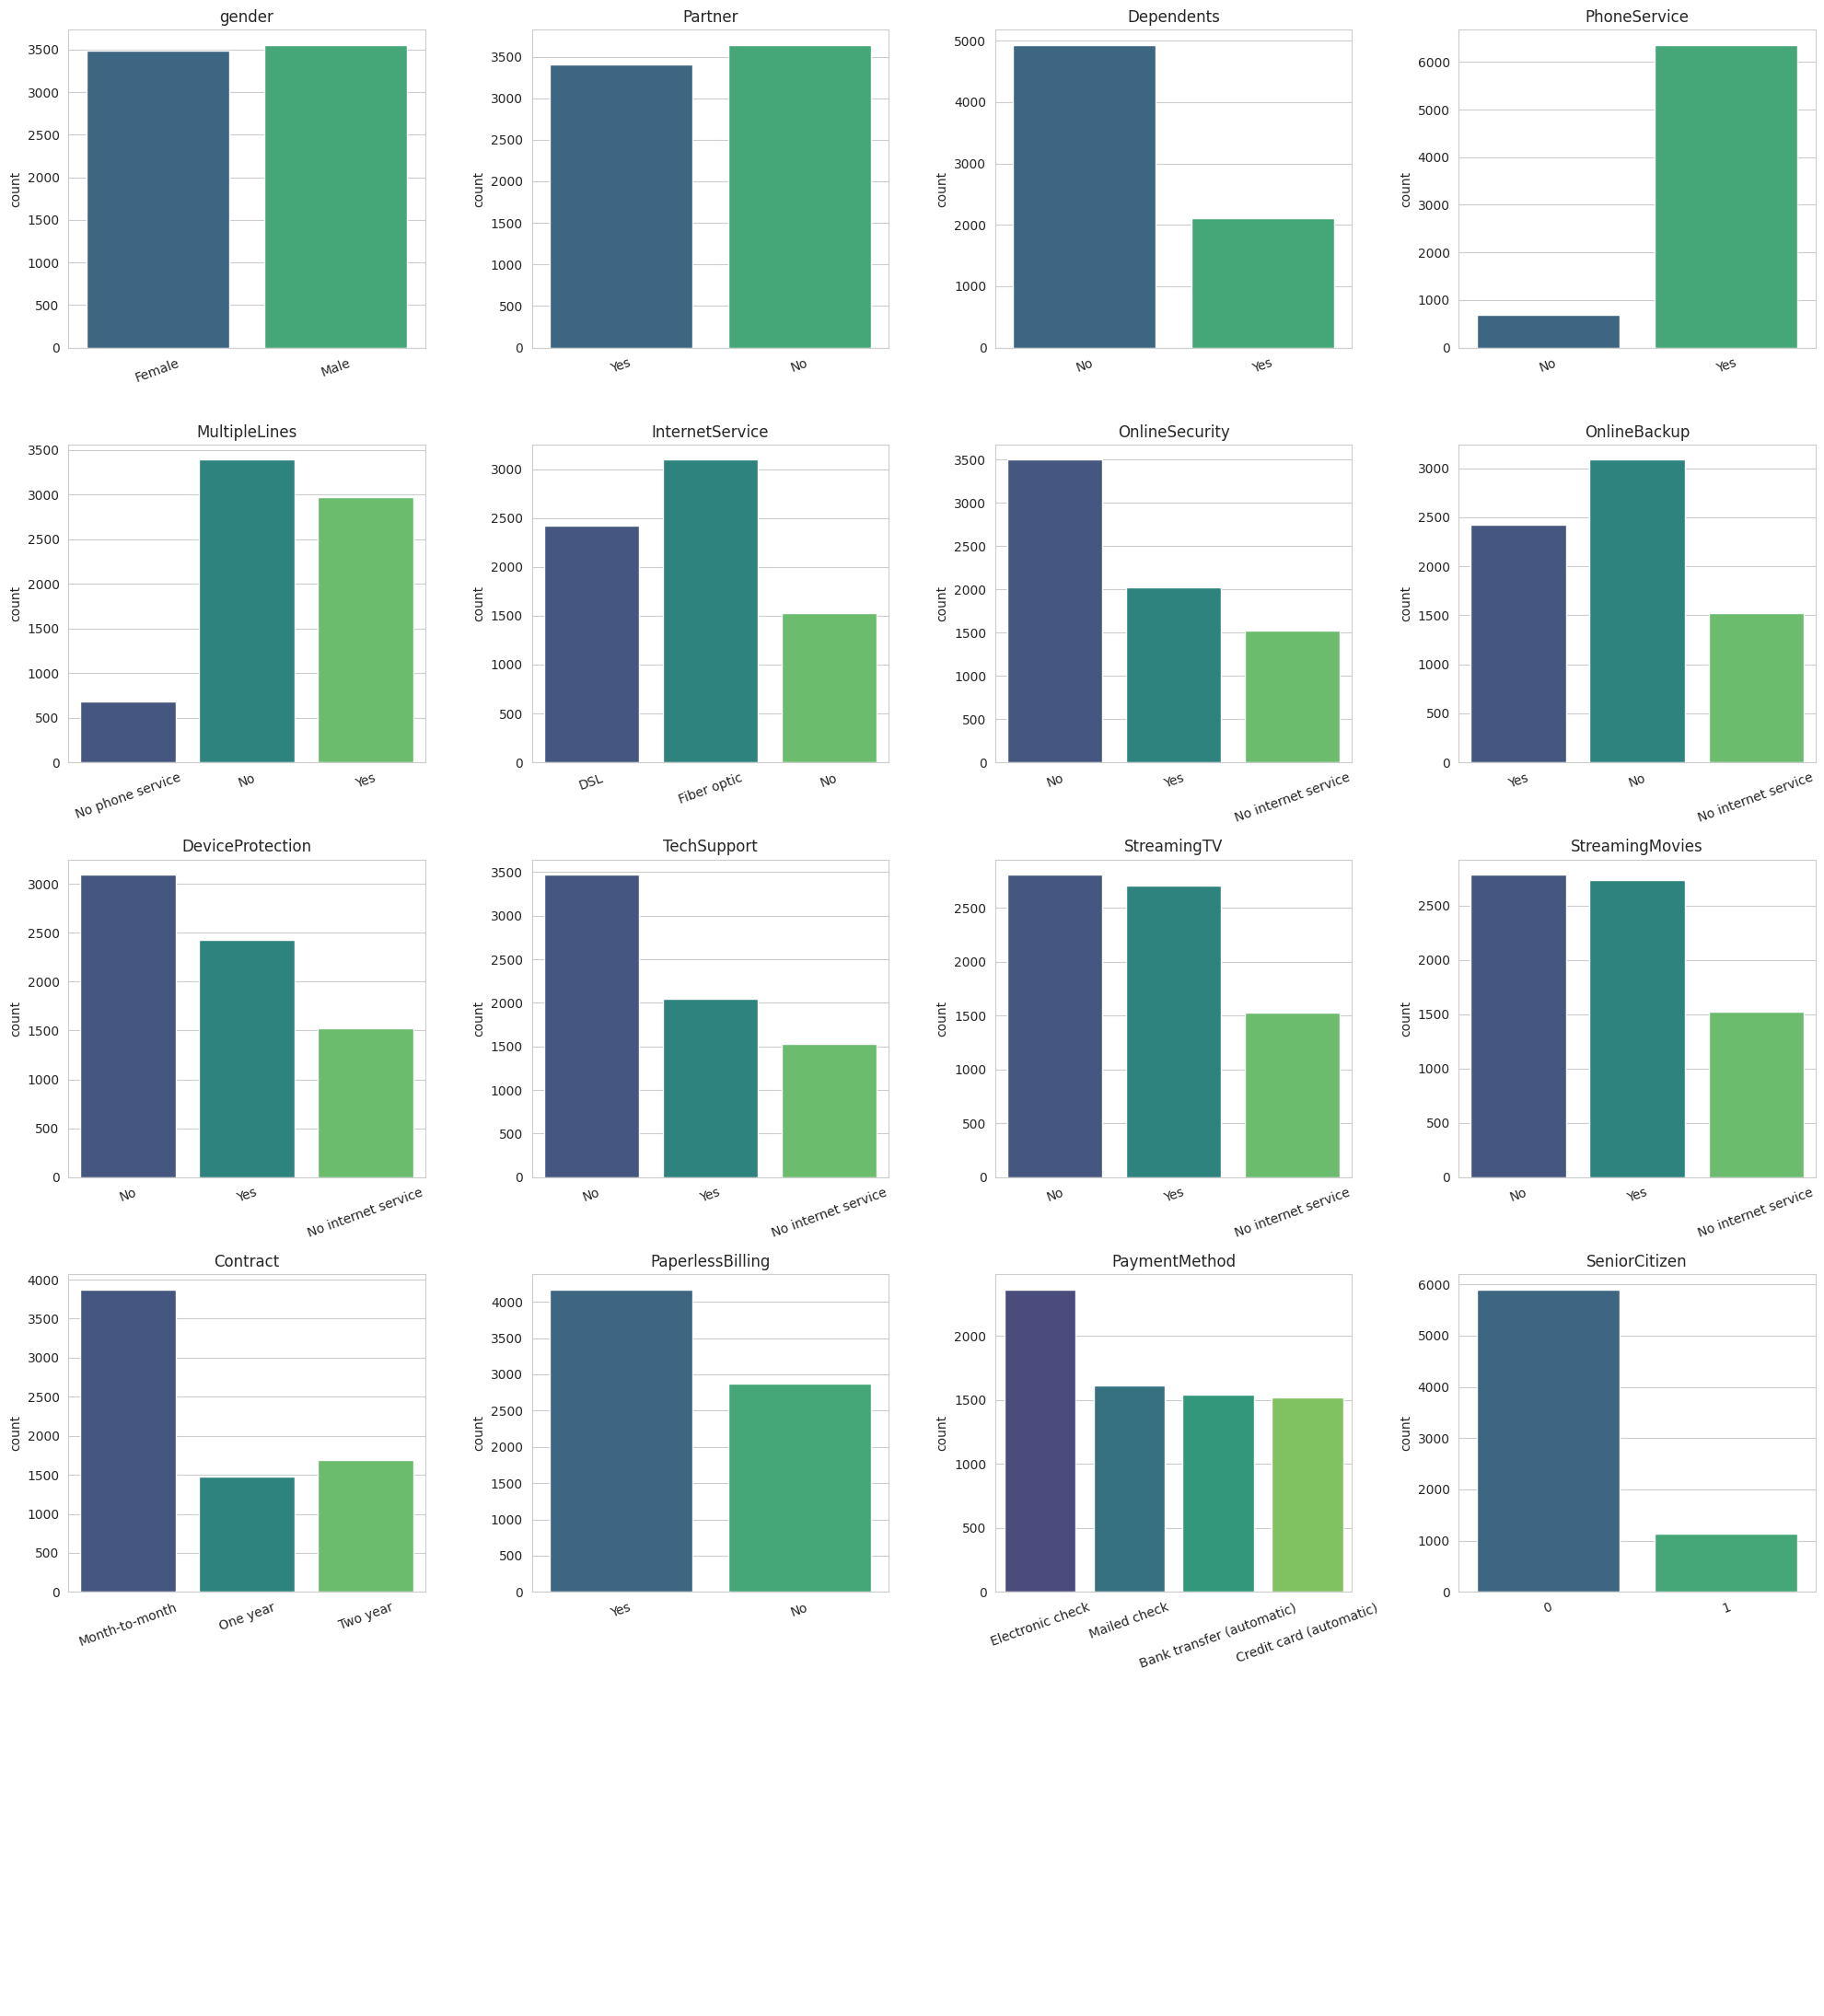

In [ ]:
cat_plot = categorical_cols + binary_numeric
fig, axes = plt.subplots(5, 4, figsize=(20, 22))
for ax, c in zip(axes.flatten(), cat_plot):
    sns.countplot(data=df, x=c, ax=ax, palette='viridis')
    ax.set_title(c); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20)
for ax in axes.flatten()[len(cat_plot):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

### 4.4 Categorical features vs Churn (churn rate per category)

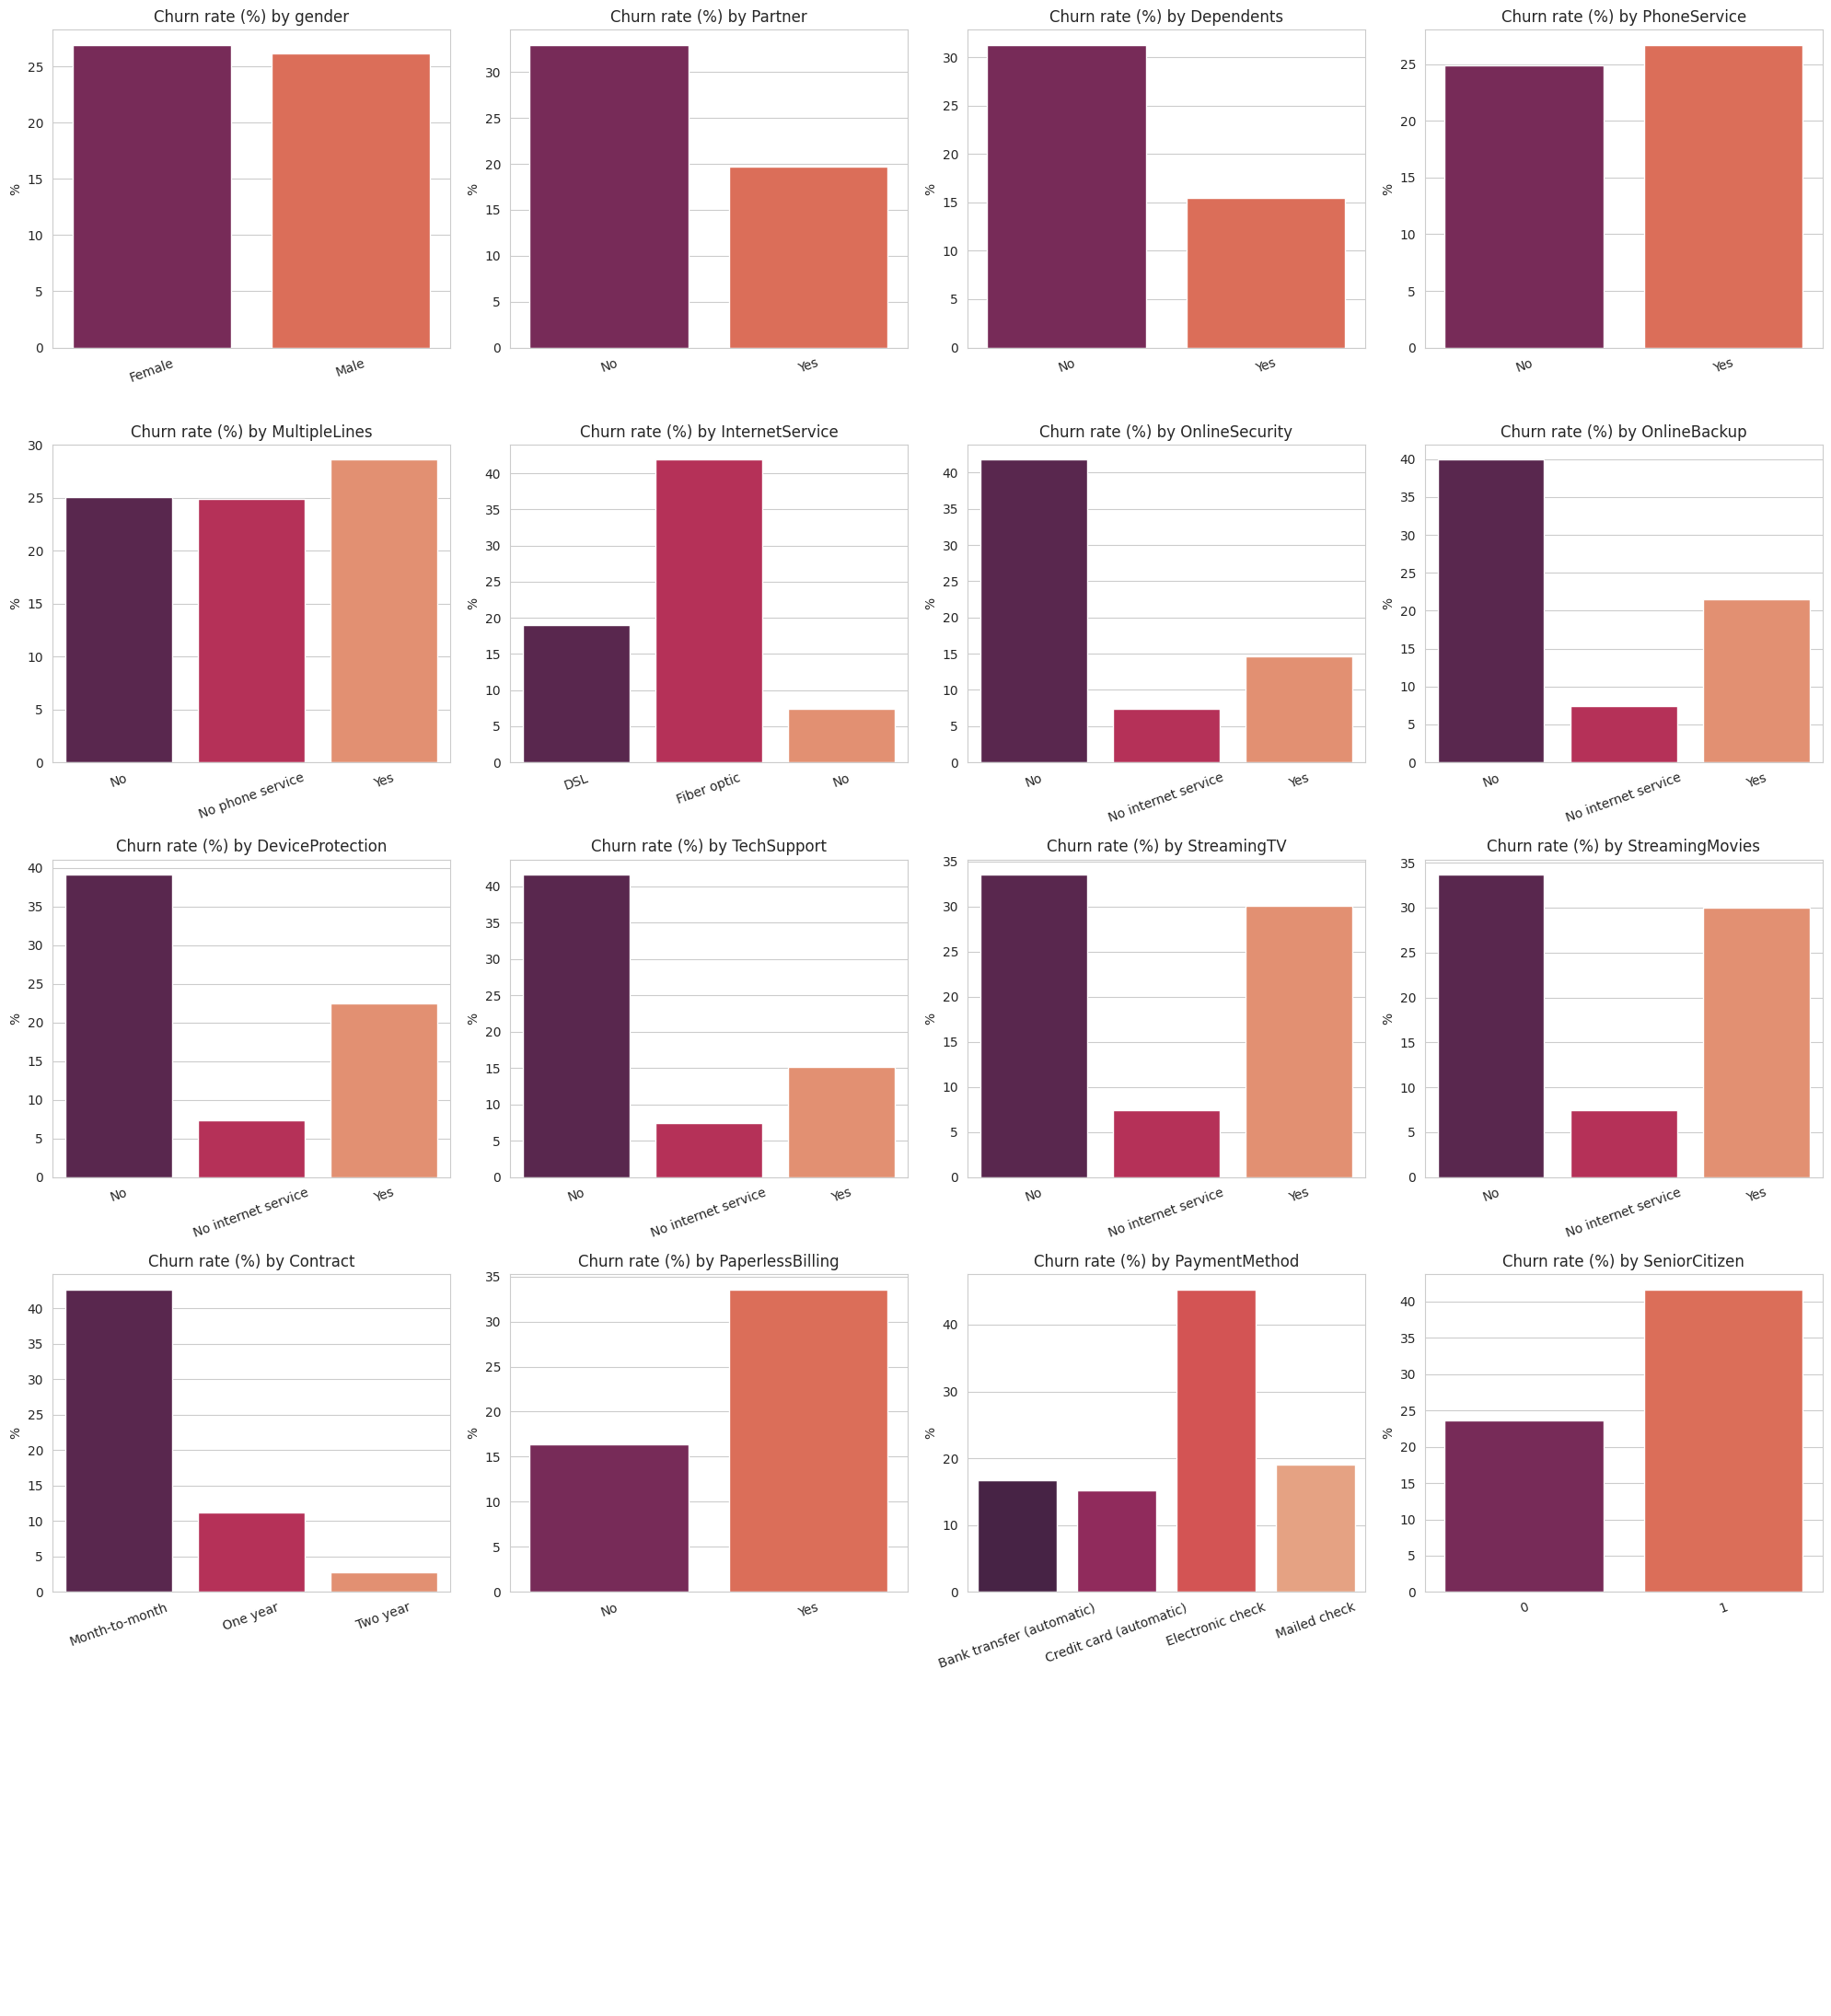

In [ ]:
fig, axes = plt.subplots(5, 4, figsize=(20, 22))
for ax, c in zip(axes.flatten(), cat_plot):
    rate = df.groupby(c)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, palette='rocket')
    ax.set_title(f'Churn rate (%) by {c}'); ax.set_xlabel(''); ax.set_ylabel('%')
    ax.tick_params(axis='x', rotation=20)
for ax in axes.flatten()[len(cat_plot):]:
    ax.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
for c in ['Contract', 'InternetService', 'PaymentMethod', 'TechSupport', 'OnlineSecurity']:
    print((df.groupby(c)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100)).round(1).to_string(), '\n')

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1 

TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2 

OnlineSecurity
No                     41.8
No internet service     7.4
Yes                    14.6 



## 5. Churn Distribution

       Count  Percentage %
Churn                     
No      5174         73.46
Yes     1869         26.54


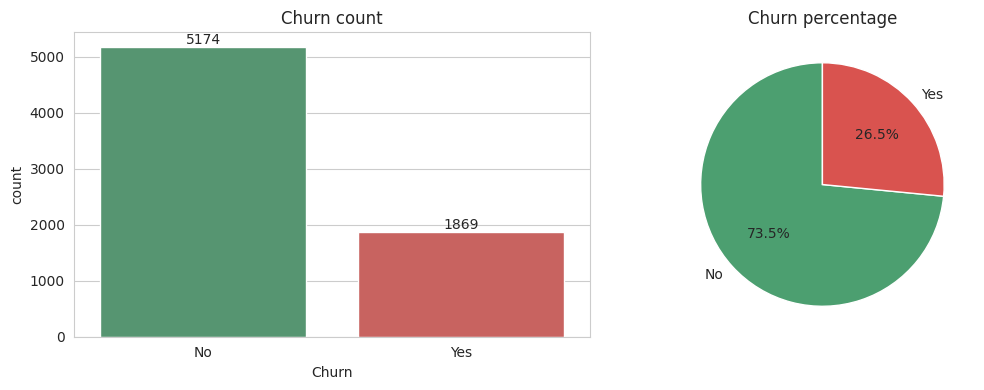

Majority/minority ratio = 2.77:1  ->  the target is IMBALANCED (about 73% No vs 27% Yes).


In [ ]:
counts = df['Churn'].value_counts()
perc = df['Churn'].value_counts(normalize=True) * 100
print(pd.DataFrame({'Count': counts, 'Percentage %': perc.round(2)}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='Churn', ax=axes[0], palette=['#4c9f70', '#d9534f'])
for p in axes[0].patches:
    axes[0].annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
axes[0].set_title('Churn count')
axes[1].pie(counts, labels=counts.index, autopct='%1.1f%%', colors=['#4c9f70', '#d9534f'], startangle=90)
axes[1].set_title('Churn percentage')
plt.tight_layout(); plt.show()

ratio = counts.max() / counts.min()
print(f"Majority/minority ratio = {ratio:.2f}:1  ->  the target is IMBALANCED (about 73% No vs 27% Yes).")

## 6. Outlier Detection (IQR method)

In [ ]:
num_feats = ['tenure', 'MonthlyCharges', 'TotalCharges']   # SeniorCitizen is binary, so IQR is meaningless for it
rows = []
outlier_mask = pd.Series(False, index=df.index)
for c in num_feats:
    Q1, Q3 = df[c].quantile(0.25), df[c].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    m = (df[c] < lower) | (df[c] > upper)
    outlier_mask |= m
    rows.append([c, Q1, Q3, IQR, lower, upper, m.sum()])
outlier_report = pd.DataFrame(rows, columns=['Feature', 'Q1', 'Q3', 'IQR', 'Lower bound', 'Upper bound', '# Outliers']).round(2)
outlier_report

,Feature,Q1,Q3,IQR,Lower bound,Upper bound,# Outliers
0,tenure,9.00,55.00,46.00,-60.00,124.00,0
1,MonthlyCharges,35.50,89.85,54.35,-46.02,171.38,0
2,TotalCharges,398.55,3786.60,3388.05,-4683.52,8868.67,0


In [ ]:
print("Rows before outlier removal:", len(df))
df_clean = df[~outlier_mask].copy()
print("Rows after outlier removal :", len(df_clean))
print("Rows removed               :", len(df) - len(df_clean))

comparison = pd.DataFrame({'Before': df[num_feats].describe().loc[['count','mean','std','min','max']].stack(),
                           'After' : df_clean[num_feats].describe().loc[['count','mean','std','min','max']].stack()}).round(2)
print(comparison)
print("\nChurn % before:", (df['Churn'].eq('Yes').mean()*100).round(2), "| after:", (df_clean['Churn'].eq('Yes').mean()*100).round(2))

Rows before outlier removal: 7043
Rows after outlier removal : 7043
Rows removed               : 0
                       Before    After
count tenure          7043.00  7043.00
      MonthlyCharges  7043.00  7043.00
      TotalCharges    7043.00  7043.00
mean  tenure            32.37    32.37
      MonthlyCharges    64.76    64.76
      TotalCharges    2279.73  2279.73
std   tenure            24.56    24.56
      MonthlyCharges    30.09    30.09
      TotalCharges    2266.79  2266.79
min   tenure             0.00     0.00
      MonthlyCharges    18.25    18.25
      TotalCharges       0.00     0.00
max   tenure            72.00    72.00
      MonthlyCharges   118.75   118.75
      TotalCharges    8684.80  8684.80

Churn % before: 26.54 | after: 26.54


**Note:** the IQR check shows that the numerical features contain no real outliers (their distributions are bounded: tenure ≤ 72 months, charges follow normal business pricing), so removal leaves the dataset unchanged. This is a good result: no customer data is lost.

## 7. Categorical Encoding

In [ ]:
df_enc = df_clean.copy()

# Binary columns -> 0/1
df_enc['gender'] = df_enc['gender'].map({'Female': 0, 'Male': 1})
for c in ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']:
    df_enc[c] = df_enc[c].map({'No': 0, 'Yes': 1})

# Multi-category columns -> One-Hot Encoding (drop_first avoids the dummy-variable trap).
# Values like "No internet service" / "No phone service" become their own category.
multi_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']
df_enc = pd.get_dummies(df_enc, columns=multi_cols, drop_first=True, dtype=int)

print("Shape after encoding:", df_enc.shape)
print("All numeric now?", all(pd.api.types.is_numeric_dtype(t) for t in df_enc.dtypes))
df_enc.head()

Shape after encoding: (7043, 31)
All numeric now? True


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,...,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,...,0,0,0,0,0,1,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,...,0,0,0,0,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,...,1,0,0,0,0,1,0,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,...,0,0,0,0,0,0,0,0,1,0


## 8. Correlation Analysis

tenure                                  -0.352
Contract_Two year                       -0.302
OnlineBackup_No internet service        -0.228
InternetService_No                      -0.228
TechSupport_No internet service         -0.228
StreamingMovies_No internet service     -0.228
DeviceProtection_No internet service    -0.228
OnlineSecurity_No internet service      -0.228
StreamingTV_No internet service         -0.228
TotalCharges                            -0.198
Contract_One year                       -0.178
OnlineSecurity_Yes                      -0.171
TechSupport_Yes                         -0.165
Dependents                              -0.164
Partner                                 -0.150
PaymentMethod_Credit card (automatic)   -0.134
PaymentMethod_Mailed check              -0.092
OnlineBackup_Yes                        -0.082
DeviceProtection_Yes                    -0.066
MultipleLines_No phone service          -0.012
gender                                  -0.009
PhoneService 

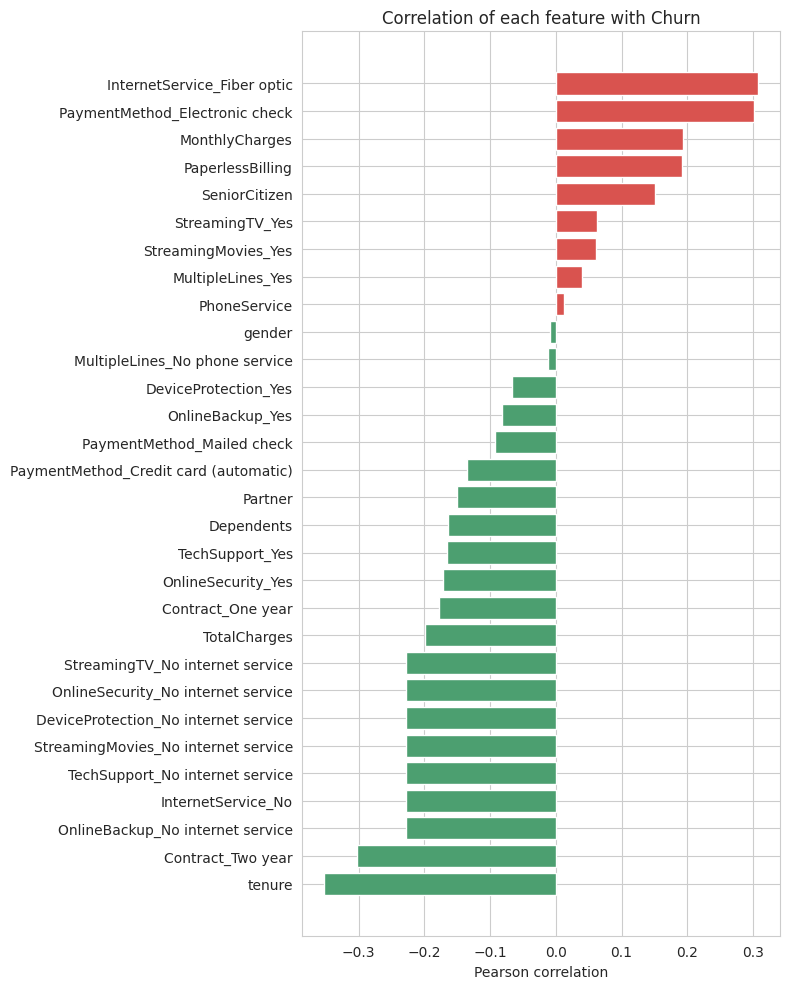

In [ ]:
corr_target = df_enc.corr()['Churn'].drop('Churn').sort_values()
print(corr_target.round(3).to_string())

plt.figure(figsize=(8, 10))
colors = ['#d9534f' if v > 0 else '#4c9f70' for v in corr_target.values]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.title('Correlation of each feature with Churn')
plt.xlabel('Pearson correlation'); plt.tight_layout(); plt.show()

In [ ]:
print("Numerical features vs Churn:")
print(df_enc[['tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']].corr()['Churn'].drop('Churn').round(3))
print("\nTop 8 strongest relationships (absolute value):")
print(corr_target.abs().sort_values(ascending=False).head(8).round(3))

Numerical features vs Churn:
tenure           -0.352
MonthlyCharges    0.193
TotalCharges     -0.198
Name: Churn, dtype: float64

Top 8 strongest relationships (absolute value):
tenure                                  0.352
InternetService_Fiber optic             0.308
Contract_Two year                       0.302
PaymentMethod_Electronic check          0.302
OnlineBackup_No internet service        0.228
InternetService_No                      0.228
DeviceProtection_No internet service    0.228
OnlineSecurity_No internet service      0.228
Name: Churn, dtype: float64


## 9. Feature Selection

In [ ]:
# Keep features with at least a weak relationship with churn (|corr| >= 0.02).
# Very low correlation columns add noise, not signal.
threshold = 0.02
selected = corr_target[corr_target.abs() >= threshold].index.tolist()
dropped = [c for c in corr_target.index if c not in selected]
print(f"Selected {len(selected)} features, dropped {len(dropped)}:")
print("Dropped:", dropped)
print("\nSelected:", selected)

Selected 27 features, dropped 3:
Dropped: ['MultipleLines_No phone service', 'gender', 'PhoneService']

Selected: ['tenure', 'Contract_Two year', 'OnlineBackup_No internet service', 'InternetService_No', 'TechSupport_No internet service', 'StreamingMovies_No internet service', 'DeviceProtection_No internet service', 'OnlineSecurity_No internet service', 'StreamingTV_No internet service', 'TotalCharges', 'Contract_One year', 'OnlineSecurity_Yes', 'TechSupport_Yes', 'Dependents', 'Partner', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Mailed check', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'MultipleLines_Yes', 'StreamingMovies_Yes', 'StreamingTV_Yes', 'SeniorCitizen', 'PaperlessBilling', 'MonthlyCharges', 'PaymentMethod_Electronic check', 'InternetService_Fiber optic']


**Why these features are appropriate**
- They show a measurable relationship with churn (contract type, tenure, internet service type, payment method, support/security add-ons, monthly charges…), which are all known business drivers of churn.
- Features such as `gender` and `PhoneService` have almost zero correlation with churn, so removing them simplifies the model without losing information.
- `customerID` is excluded: it is a unique identifier with no predictive meaning.
- `TotalCharges` is highly correlated with `tenure` and `MonthlyCharges` (it is roughly tenure × monthly). It is kept since it is informative, but we note the multicollinearity.

## 10. Missing Value Handling

In [ ]:
model_df = df_enc[selected + ['Churn']]
print("Total missing values:", model_df.isnull().sum().sum())
model_df = model_df.fillna(model_df.median())   # safety net, nothing to fill
print("Missing values after handling:", model_df.isnull().sum().sum())
print("Final modeling dataset shape:", model_df.shape)

Total missing values: 0
Missing values after handling: 0
Final modeling dataset shape: (7043, 28)


## 11. Feature and Target Preparation

In [ ]:
X = model_df.drop(columns='Churn')
y = model_df['Churn']
print("X shape:", X.shape, "| y shape:", y.shape)
print("y distribution:\n", y.value_counts())

X shape: (7043, 27) | y shape: (7043,)
y distribution:
 Churn
0    5174
1    1869
Name: count, dtype: int64


## 12. Train-Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nChurn rate  full : %.2f%%" % (y.mean()*100))
print("Churn rate  train: %.2f%%" % (y_train.mean()*100))
print("Churn rate  test : %.2f%%" % (y_test.mean()*100))

Train: (5634, 27) | Test: (1409, 27)

Churn rate  full : 26.54%
Churn rate  train: 26.54%
Churn rate  test : 26.54%


## 13. Feature Scaling

In [ ]:
# Only the continuous columns need scaling; the dummy/binary columns are already 0/1.
scale_cols = [c for c in ['tenure', 'MonthlyCharges', 'TotalCharges'] if c in X.columns]
scaler = StandardScaler()
X_train_s, X_test_s = X_train.copy(), X_test.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train[scale_cols])   # fit on TRAIN only
X_test_s[scale_cols]  = scaler.transform(X_test[scale_cols])         # transform only -> no leakage
print("Scaled columns:", scale_cols)
print(X_train_s[scale_cols].describe().loc[['mean', 'std']].round(3))

Scaled columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
      tenure  MonthlyCharges  TotalCharges
mean    -0.0            -0.0           0.0
std      1.0             1.0           1.0


## 14. Classification Models

### Model 1: Logistic Regression

In [ ]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_s, y_train)
y_pred_lr = log_reg.predict(X_test_s)
print("Logistic Regression trained. Sample predictions:", y_pred_lr[:15])

Logistic Regression trained. Sample predictions: [0 1 0 0 0 1 0 0 0 0 0 0 0 1 0]


### Model 2: Decision Tree

In [ ]:
# max_depth is limited to avoid overfitting (an unrestricted tree memorizes the training set)
dtree = DecisionTreeClassifier(max_depth=5, random_state=42)
dtree.fit(X_train_s, y_train)
y_pred_dt = dtree.predict(X_test_s)
print("Decision Tree trained. Sample predictions:", y_pred_dt[:15])
print("Train accuracy: %.3f | Test accuracy: %.3f" % (dtree.score(X_train_s, y_train), dtree.score(X_test_s, y_test)))

Decision Tree trained. Sample predictions: [0 1 0 0 0 0 0 0 0 0 0 0 0 1 0]
Train accuracy: 0.802 | Test accuracy: 0.794


## 15. Model Evaluation

In [ ]:
def evaluate(name, y_true, y_pred):
    res = {'Model': name,
           'Accuracy': accuracy_score(y_true, y_pred),
           'Precision': precision_score(y_true, y_pred),
           'Recall': recall_score(y_true, y_pred),
           'F1-Score': f1_score(y_true, y_pred)}
    print("="*60); print(name); print("="*60)
    for k in ['Accuracy','Precision','Recall','F1-Score']:
        print(f"{k:10s}: {res[k]:.4f}")
    print("\nClassification report:\n", classification_report(y_true, y_pred, target_names=['No Churn', 'Churn']))
    return res

res_lr = evaluate('Logistic Regression', y_test, y_pred_lr)
res_dt = evaluate('Decision Tree', y_test, y_pred_dt)

Logistic Regression
Accuracy  : 0.8055
Precision : 0.6582
Recall    : 0.5561
F1-Score  : 0.6029

Classification report:
               precision    recall  f1-score   support

    No Churn       0.85      0.90      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Decision Tree
Accuracy  : 0.7942
Precision : 0.6312
Recall    : 0.5401
F1-Score  : 0.5821

Classification report:
               precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1035
       Churn       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



## 16. Confusion Matrix

Logistic Regression  -> TN=927  FP=108  FN=166  TP=208
Decision Tree        -> TN=917  FP=118  FN=172  TP=202


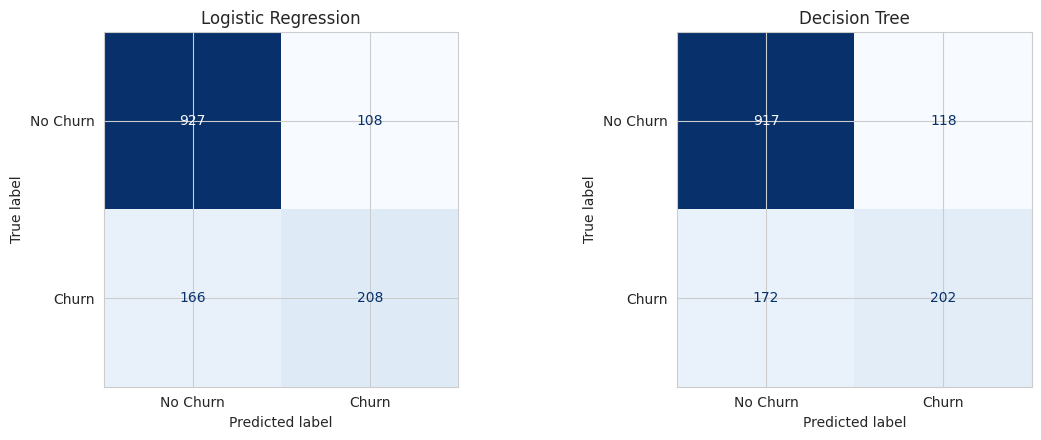

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, name, pred in zip(axes, ['Logistic Regression', 'Decision Tree'], [y_pred_lr, y_pred_dt]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=['No Churn', 'Churn']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
    tn, fp, fn, tp = cm.ravel()
    print(f"{name:20s} -> TN={tn}  FP={fp}  FN={fn}  TP={tp}")
plt.tight_layout(); plt.show()

- **TN (True Negative):** customer stayed and the model predicted stay.
- **TP (True Positive):** customer churned and the model predicted churn.
- **FP (False Positive):** customer stayed but the model predicted churn (wasted retention offer).
- **FN (False Negative):** customer churned but the model predicted stay (a lost customer we failed to catch — the costliest error).

## 17. Model Comparison

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.8055,0.6582,0.5561,0.6029
Decision Tree,0.7942,0.6312,0.5401,0.5821


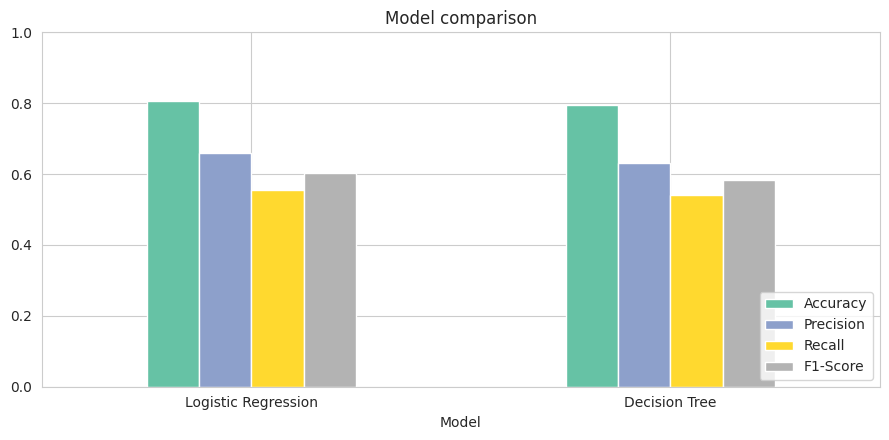

In [ ]:
comparison_df = pd.DataFrame([res_lr, res_dt]).set_index('Model').round(4)
display(comparison_df)
comparison_df.plot(kind='bar', figsize=(9, 4.5), rot=0, colormap='Set2')
plt.ylim(0, 1); plt.title('Model comparison'); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

## 18. Final Analysis

In [ ]:
for q, m in [('1. Highest accuracy ', 'Accuracy'), ('2. Highest precision', 'Precision'),
             ('3. Highest recall   ', 'Recall'), ('4. Highest F1-score ', 'F1-Score')]:
    best = comparison_df[m].idxmax()
    print(f"{q}: {best}  ({comparison_df[m].max():.4f})")
print("\n7. Is the dataset imbalanced? Yes -> %.1f%% No vs %.1f%% Yes" % ((1-y.mean())*100, y.mean()*100))
print("\n8. Top factors linked to churn (by |correlation|):")
top = corr_target[~corr_target.index.str.endswith('No internet service')]   # these 7 dummies duplicate InternetService_No
print(top.reindex(top.abs().sort_values(ascending=False).index).head(8).round(3).to_string())

1. Highest accuracy : Logistic Regression  (0.8055)
2. Highest precision: Logistic Regression  (0.6582)
3. Highest recall   : Logistic Regression  (0.5561)
4. Highest F1-score : Logistic Regression  (0.6029)

7. Is the dataset imbalanced? Yes -> 73.5% No vs 26.5% Yes

8. Top factors linked to churn (by |correlation|):
tenure                           -0.352
InternetService_Fiber optic       0.308
Contract_Two year                -0.302
PaymentMethod_Electronic check    0.302
InternetService_No               -0.228
TotalCharges                     -0.198
MonthlyCharges                    0.193
PaperlessBilling                  0.192


**Answers**

1. **Highest accuracy:** Logistic Regression (≈ 0.806 vs 0.794).
2. **Highest precision:** Logistic Regression (≈ 0.658 vs 0.631).
3. **Highest recall:** Logistic Regression (≈ 0.556 vs 0.540).
4. **Highest F1-score:** Logistic Regression (≈ 0.603 vs 0.582).
5. **Better model for churn prediction:** **Logistic Regression** — it wins on all four metrics, catches more real churners (208 vs 202 TP) and raises fewer false alarms (108 vs 118 FP). It is also simpler and its coefficients are easy to interpret. The gap is small, though, so both models perform similarly.
6. **Why accuracy alone is not enough:** the data is imbalanced (~73.5% stay / 26.5% churn). A useless model that predicts "No churn" for everybody would already score ≈ 73.5% accuracy while catching **zero** churners. Accuracy hides how the model performs on the minority class we actually care about. Recall tells us how many churners we catch, precision tells us how many of our alerts are right, and F1 balances both.
7. **Is the dataset imbalanced?** Yes: 5,174 customers stayed (73.5%) vs 1,869 churned (26.5%), a ratio of about 2.8 : 1.
8. **Most important factors associated with churn:**
   - **Tenure** (strongest, negative): new customers churn much more (avg 18 months for churners vs 37.6 for stayers).
   - **Contract type:** month-to-month churn is 42.7% vs 11.3% (1 year) and 2.8% (2 years).
   - **Internet service:** Fiber optic customers churn at 41.9% vs 19.0% (DSL) and 7.4% (no internet).
   - **Payment method:** electronic check users churn at 45.3% vs about 15–19% for other methods.
   - **No Online Security / Tech Support:** churn ≈ 42% without them vs ≈ 15% with them.
   - **Higher monthly charges, paperless billing, and senior citizens** also show a positive association with churn; having a partner or dependents shows a negative one.
   - Gender and phone service have almost no effect.

## 19. Final Conclusion

**What was done:** we loaded the Telco churn data (7,043 customers, 21 columns), fixed `TotalCharges` (text → numeric, 11 blanks filled with 0 because those customers have tenure = 0), dropped `customerID`, explored the data, checked outliers with IQR (none found, so no rows were removed), encoded all categorical variables, selected 27 features by correlation with churn, did a stratified 80/20 split, scaled the numeric columns using the training set only, and trained Logistic Regression and a Decision Tree (max_depth = 5).

**Main EDA findings:** about 26.5% of customers churn. Churn is concentrated among new customers (low tenure), month-to-month contracts, fiber-optic internet, electronic-check payment, and customers without security/tech-support add-ons.

**Best model:** Logistic Regression (accuracy ≈ 0.806, precision ≈ 0.658, recall ≈ 0.556, F1 ≈ 0.603), slightly ahead of the Decision Tree on every metric.

**Most important metric:** **Recall** (together with F1), because missing a customer who is about to leave (false negative) costs more than sending a retention offer to someone who would have stayed. Accuracy is misleading on imbalanced data.

**Suitability:** the model is a reasonable starting point and clearly picks up the real churn drivers, but its recall of ~56% means it still misses ~44% of churners. For production use it should be improved, e.g. with `class_weight='balanced'`, lowering the decision threshold, using resampling (SMOTE), cross-validation, or stronger models such as Random Forest / Gradient Boosting.